# B04a: STFT and Spectrograms

**Part 1 of 2** | ⏱️ **Duration:** 45 minutes

## Prerequisites
- [A02: The Frequency Domain](../../A_signal_fundamentals/A02_frequency_domain.ipynb) — FFT basics
- [A03: Power Spectrum](../../A_signal_fundamentals/A03_power_spectrum_frequency_bands.ipynb) — Power spectral density

## Learning Objectives
By the end of this notebook, you will be able to:
- Explain why the Fourier transform loses temporal information
- Understand the time-frequency uncertainty trade-off
- Implement the Short-Time Fourier Transform (STFT) from scratch
- Choose appropriate window length and overlap parameters
- Interpret spectrograms in the context of EEG signal analysis


## Table of Contents

1. [Introduction — The Problem with FFT](#section-1-introduction)
2. [Intuition — Windows in Time](#section-2-intuition)
3. [Short-Time Fourier Transform (STFT)](#section-3-stft)
4. [Summary](#summary)
5. [Discussion Questions](#discussion-questions)
6. [External Resources](#external-resources)


In [1]:
# ============================================================================
# IMPORTS AND SETUP
# ============================================================================
import sys
from pathlib import Path
from typing import Tuple, Optional, Union

import numpy as np
from numpy.typing import NDArray
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import hilbert, stft, spectrogram
from scipy.fft import fft, ifft, fftfreq

# Add src to path for local imports
sys.path.insert(0, str(Path.cwd().parents[2]))

from src.colors import COLORS
from src.filtering import bandpass_filter

# Color aliases for convenience - following style guide
PRIMARY_BLUE = COLORS["signal_1"]      # Sky Blue
PRIMARY_RED = COLORS["signal_2"]       # Rose Pink
PRIMARY_GREEN = COLORS["signal_3"]     # Sage Green
SECONDARY_PURPLE = COLORS["high_sync"] # Purple
SECONDARY_ORANGE = COLORS["signal_4"]  # Golden (used as orange)
ACCENT_PURPLE = COLORS["signal_5"]     # Lavender
ACCENT_GOLD = COLORS["signal_4"]       # Golden

# Sampling frequency (standard EEG)
fs = 256  # Hz

# Set random seed for reproducibility
np.random.seed(42)

print("✓ Imports successful!")
print(f"NumPy version: {np.__version__}")

✓ Imports successful!
NumPy version: 2.3.5


---

## 1. Introduction — The Problem with FFT

The **Fast Fourier Transform (FFT)** is a powerful tool that decomposes a signal into its frequency components. However, it has a fundamental limitation:

**FFT tells us WHICH frequencies are present, but not WHEN.**

This is problematic for EEG analysis because:

- Neural oscillations are **non-stationary**: they come and go
- Alpha bursts appear and disappear over seconds
- Cognitive states change during an experiment
- Social interactions involve dynamic synchronization

FFT assumes the signal is **stationary** (same statistics throughout), which is rarely true for brain signals.

**Solution**: We need methods that provide BOTH time AND frequency information — this is **time-frequency analysis**.

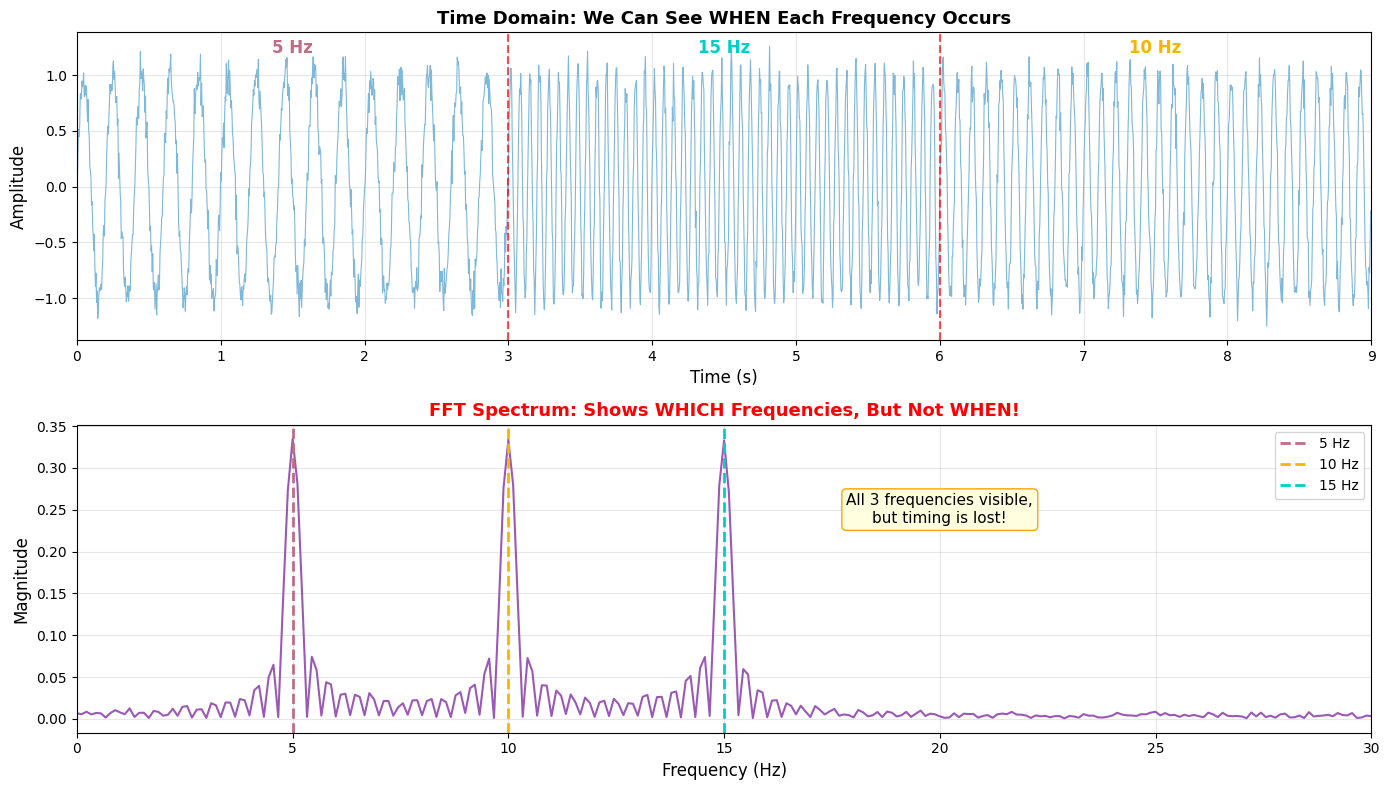

→ FFT reveals all three frequencies (5, 10, 15 Hz)
→ But we can't tell that 5 Hz was first, 15 Hz second, 10 Hz last!
→ For non-stationary signals, FFT alone is insufficient.


In [2]:
# ============================================================================
# VISUALIZATION 1: FFT Loses Temporal Information
# ============================================================================

# Create a non-stationary signal: frequency changes over time
duration = 9.0  # seconds
t = np.arange(0, duration, 1/fs)

# Three segments with different frequencies
# 0-3s: 5 Hz, 3-6s: 15 Hz, 6-9s: 10 Hz
segment1 = np.sin(2 * np.pi * 5 * t[t < 3])
segment2 = np.sin(2 * np.pi * 15 * t[(t >= 3) & (t < 6)])
segment3 = np.sin(2 * np.pi * 10 * t[t >= 6])

# Concatenate
signal_nonstat = np.concatenate([segment1, segment2, segment3])

# Add small noise
signal_nonstat += 0.1 * np.random.randn(len(signal_nonstat))

# Compute FFT
n = len(signal_nonstat)
fft_result = fft(signal_nonstat)
frequencies = fftfreq(n, 1/fs)
magnitude = np.abs(fft_result) / n

# Only positive frequencies
pos_mask = frequencies >= 0
freq_pos = frequencies[pos_mask]
mag_pos = 2 * magnitude[pos_mask]  # Double for one-sided

# Create figure
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Top: Time domain
axes[0].plot(t, signal_nonstat, color=PRIMARY_BLUE, linewidth=0.8)
axes[0].axvline(x=3, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axvline(x=6, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].annotate('5 Hz', xy=(1.5, 1.2), ha='center', fontsize=12, fontweight='bold', color=COLORS["theta"])
axes[0].annotate('15 Hz', xy=(4.5, 1.2), ha='center', fontsize=12, fontweight='bold', color=COLORS["beta"])
axes[0].annotate('10 Hz', xy=(7.5, 1.2), ha='center', fontsize=12, fontweight='bold', color=COLORS["alpha"])
axes[0].set_xlabel('Time (s)', fontsize=12)
axes[0].set_ylabel('Amplitude', fontsize=12)
axes[0].set_title('Time Domain: We Can See WHEN Each Frequency Occurs', fontsize=13, fontweight='bold')
axes[0].set_xlim(0, 9)
axes[0].grid(True, alpha=0.3)

# Bottom: Frequency domain (FFT)
axes[1].plot(freq_pos, mag_pos, color=SECONDARY_PURPLE, linewidth=1.5)
axes[1].axvline(x=5, color=COLORS["theta"], linestyle='--', linewidth=2, label='5 Hz')
axes[1].axvline(x=10, color=COLORS["alpha"], linestyle='--', linewidth=2, label='10 Hz')
axes[1].axvline(x=15, color=COLORS["beta"], linestyle='--', linewidth=2, label='15 Hz')
axes[1].set_xlabel('Frequency (Hz)', fontsize=12)
axes[1].set_ylabel('Magnitude', fontsize=12)
axes[1].set_title('FFT Spectrum: Shows WHICH Frequencies, But Not WHEN!', fontsize=13, fontweight='bold', color='red')
axes[1].set_xlim(0, 30)
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

# Add annotation
axes[1].annotate('All 3 frequencies visible,\nbut timing is lost!', 
                 xy=(20, mag_pos.max()*0.7), fontsize=11, ha='center',
                 bbox=dict(boxstyle='round', facecolor='lightyellow', edgecolor='orange'))

plt.tight_layout()
plt.show()

print("→ FFT reveals all three frequencies (5, 10, 15 Hz)")
print("→ But we can't tell that 5 Hz was first, 15 Hz second, 10 Hz last!")
print("→ For non-stationary signals, FFT alone is insufficient.")

---

## 2. Intuition — Windows in Time

The solution is intuitive: **compute the FFT on SHORT windows of the signal**, then slide the window through time.

This gives us frequency content at each time point!

However, there's a fundamental **trade-off**:

| Window Size | Time Resolution | Frequency Resolution |
|-------------|-----------------|---------------------|
| **Short** | Good (precise timing) | Poor (frequencies blur together) |
| **Long** | Poor (timing uncertain) | Good (frequencies well-separated) |

This is the **Heisenberg uncertainty principle** for signals:

$$\Delta t \times \Delta f \geq \text{constant}$$

**You cannot have perfect resolution in BOTH time AND frequency simultaneously.**

This is not a limitation of our methods — it's a fundamental property of signals!

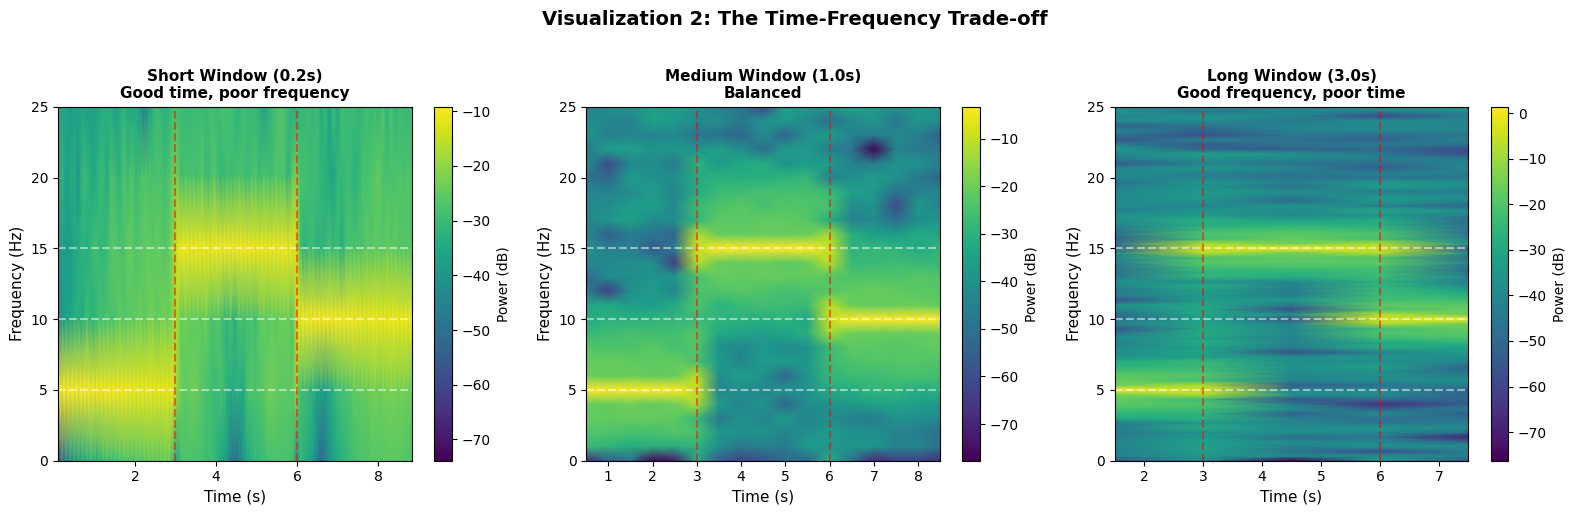

Observations:
- Short window (left): Transitions are sharp, but frequencies blur vertically
- Medium window (center): Reasonable balance
- Long window (right): Frequencies are distinct, but transitions are smeared

→ This is the Heisenberg uncertainty principle in action!


In [3]:
# ============================================================================
# VISUALIZATION 2: Time-Frequency Trade-off with Different Window Sizes
# ============================================================================

from scipy.signal import spectrogram as scipy_spectrogram

# Use the non-stationary signal from before
window_sizes = [0.2, 1.0, 3.0]  # seconds
titles = ['Short Window (0.2s)\nGood time, poor frequency', 
          'Medium Window (1.0s)\nBalanced',
          'Long Window (3.0s)\nGood frequency, poor time']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, (win_sec, title) in enumerate(zip(window_sizes, titles)):
    nperseg = int(win_sec * fs)
    
    # Compute spectrogram
    f, t_spec, Sxx = scipy_spectrogram(signal_nonstat, fs=fs, nperseg=nperseg, 
                                        noverlap=nperseg//2)
    
    # Plot
    im = axes[idx].pcolormesh(t_spec, f, 10*np.log10(Sxx + 1e-10), 
                               shading='gouraud', cmap='viridis')
    axes[idx].set_ylim(0, 25)
    axes[idx].set_xlabel('Time (s)', fontsize=11)
    axes[idx].set_ylabel('Frequency (Hz)', fontsize=11)
    axes[idx].set_title(title, fontsize=11, fontweight='bold')
    
    # Mark true frequencies
    axes[idx].axhline(y=5, color='white', linestyle='--', alpha=0.5)
    axes[idx].axhline(y=10, color='white', linestyle='--', alpha=0.5)
    axes[idx].axhline(y=15, color='white', linestyle='--', alpha=0.5)
    
    # Mark transitions
    axes[idx].axvline(x=3, color='red', linestyle='--', alpha=0.5)
    axes[idx].axvline(x=6, color='red', linestyle='--', alpha=0.5)
    
    plt.colorbar(im, ax=axes[idx], label='Power (dB)')

plt.suptitle('Visualization 2: The Time-Frequency Trade-off', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Observations:")
print("- Short window (left): Transitions are sharp, but frequencies blur vertically")
print("- Medium window (center): Reasonable balance")
print("- Long window (right): Frequencies are distinct, but transitions are smeared")
print("\n→ This is the Heisenberg uncertainty principle in action!")

---

## 3. Short-Time Fourier Transform (STFT)

The **Short-Time Fourier Transform (STFT)** formalizes the windowed FFT approach:

1. Apply a **window function** (Hann, Hamming) to a segment of the signal
2. Compute FFT of the windowed segment
3. Slide the window forward and repeat
4. Result: 2D matrix of complex coefficients (frequency × time)

**Key parameters**:
- `nperseg`: Window length in samples → determines frequency resolution
- `noverlap`: Overlap between windows → determines time sampling density
- `window`: Window type (Hann reduces spectral leakage)

The **spectrogram** is the squared magnitude of STFT: $|\text{STFT}(t, f)|^2$

In [4]:
# ============================================================================
# FUNCTION 1: compute_stft
# ============================================================================

def compute_stft(
    signal: NDArray[np.floating],
    fs: float,
    nperseg: int = 256,
    noverlap: Optional[int] = None,
    window: str = "hann"
) -> Tuple[NDArray[np.floating], NDArray[np.floating], NDArray[np.complexfloating]]:
    """
    Compute Short-Time Fourier Transform of a signal.
    
    Parameters
    ----------
    signal : NDArray[np.floating]
        Input signal.
    fs : float
        Sampling frequency in Hz.
    nperseg : int, optional
        Window length in samples (default: 256).
    noverlap : int, optional
        Overlap between windows (default: nperseg // 2).
    window : str, optional
        Window type (default: 'hann').
    
    Returns
    -------
    frequencies : NDArray[np.floating]
        Frequency values in Hz.
    times : NDArray[np.floating]
        Time values in seconds.
    stft_matrix : NDArray[np.complexfloating]
        Complex STFT matrix (frequency × time).
    """
    if noverlap is None:
        noverlap = nperseg // 2
    
    frequencies, times, stft_matrix = stft(signal, fs=fs, nperseg=nperseg,
                                            noverlap=noverlap, window=window)
    
    return frequencies, times, stft_matrix

In [5]:
# ============================================================================
# FUNCTION 2: compute_spectrogram
# ============================================================================

def compute_spectrogram(
    signal: NDArray[np.floating],
    fs: float,
    nperseg: int = 256,
    noverlap: Optional[int] = None,
    window: str = "hann"
) -> Tuple[NDArray[np.floating], NDArray[np.floating], NDArray[np.floating]]:
    """
    Compute power spectrogram (squared magnitude of STFT).
    
    Parameters
    ----------
    signal : NDArray[np.floating]
        Input signal.
    fs : float
        Sampling frequency in Hz.
    nperseg : int, optional
        Window length in samples (default: 256).
    noverlap : int, optional
        Overlap between windows (default: nperseg // 2).
    window : str, optional
        Window type (default: 'hann').
    
    Returns
    -------
    frequencies : NDArray[np.floating]
        Frequency values in Hz.
    times : NDArray[np.floating]
        Time values in seconds.
    power : NDArray[np.floating]
        Power spectrogram (frequency × time).
    """
    frequencies, times, stft_matrix = compute_stft(signal, fs, nperseg, 
                                                    noverlap, window)
    power = np.abs(stft_matrix) ** 2
    
    return frequencies, times, power

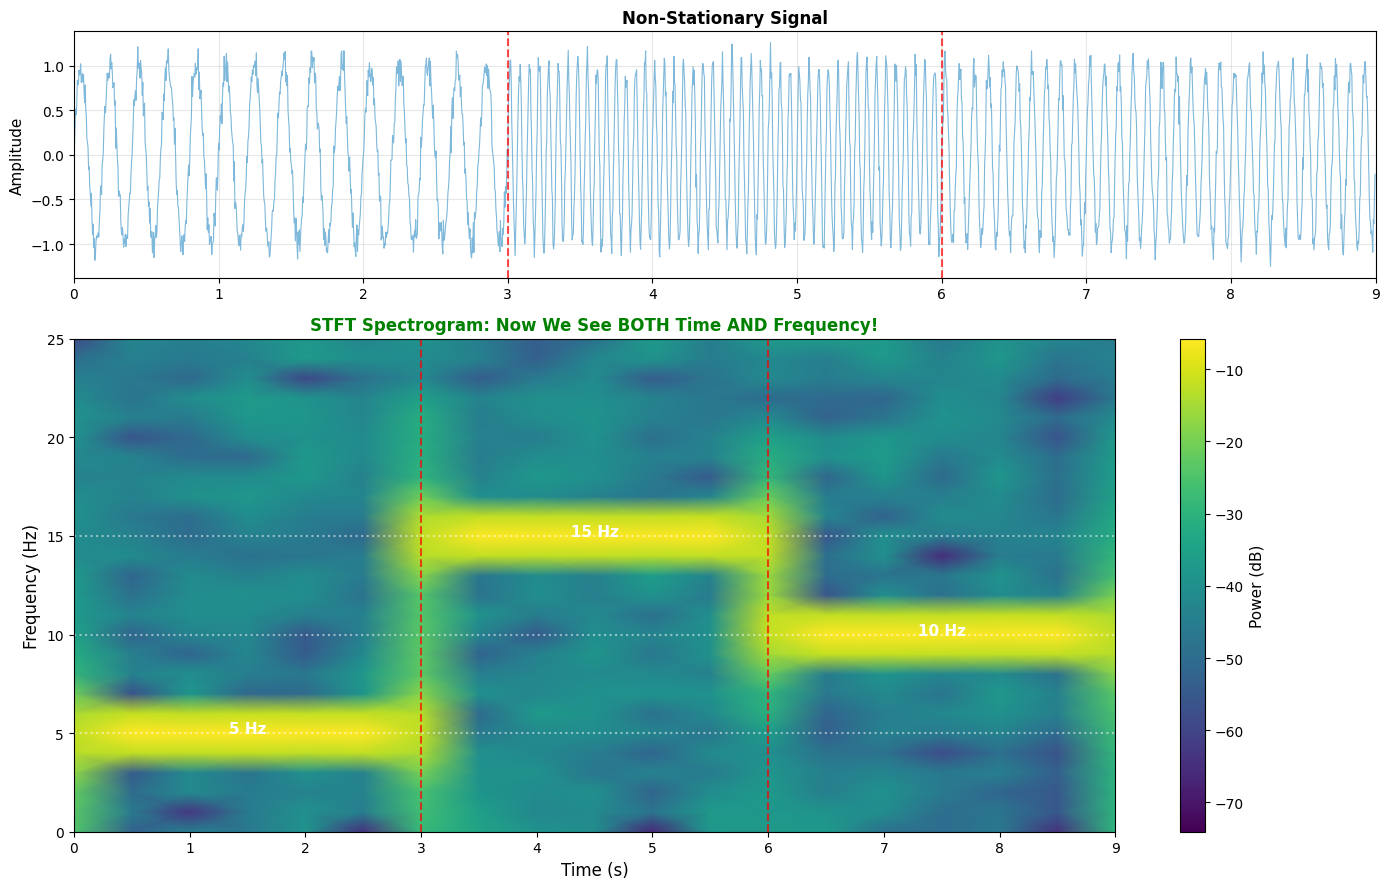

✓ The spectrogram clearly shows:
  - 5 Hz from 0-3s
  - 15 Hz from 3-6s
  - 10 Hz from 6-9s
→ We now have BOTH time and frequency information!


In [6]:
# ============================================================================
# VISUALIZATION 3: STFT Spectrogram
# ============================================================================

# Compute spectrogram with balanced parameters
nperseg_stft = int(1.0 * fs)  # 1-second window
freqs_stft, times_stft, power_stft = compute_spectrogram(signal_nonstat, fs, 
                                                          nperseg=nperseg_stft)

# Create figure
fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={'height_ratios': [1, 2]})

# Top: Time domain signal
axes[0].plot(t, signal_nonstat, color=PRIMARY_BLUE, linewidth=0.8)
axes[0].axvline(x=3, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].axvline(x=6, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
axes[0].set_ylabel('Amplitude', fontsize=11)
axes[0].set_title('Non-Stationary Signal', fontsize=12, fontweight='bold')
axes[0].set_xlim(0, 9)
axes[0].grid(True, alpha=0.3)

# Bottom: Spectrogram
im = axes[1].pcolormesh(times_stft, freqs_stft, 10*np.log10(power_stft + 1e-10),
                         shading='gouraud', cmap='viridis')
axes[1].set_xlabel('Time (s)', fontsize=12)
axes[1].set_ylabel('Frequency (Hz)', fontsize=12)
axes[1].set_title('STFT Spectrogram: Now We See BOTH Time AND Frequency!', 
                  fontsize=12, fontweight='bold', color='green')
axes[1].set_ylim(0, 25)

# Mark transitions
axes[1].axvline(x=3, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
axes[1].axvline(x=6, color='red', linestyle='--', linewidth=1.5, alpha=0.7)

# Mark frequencies
axes[1].axhline(y=5, color='white', linestyle=':', alpha=0.5)
axes[1].axhline(y=10, color='white', linestyle=':', alpha=0.5)
axes[1].axhline(y=15, color='white', linestyle=':', alpha=0.5)

# Annotate
axes[1].annotate('5 Hz', xy=(1.5, 5), color='white', fontweight='bold', fontsize=11, ha='center')
axes[1].annotate('15 Hz', xy=(4.5, 15), color='white', fontweight='bold', fontsize=11, ha='center')
axes[1].annotate('10 Hz', xy=(7.5, 10), color='white', fontweight='bold', fontsize=11, ha='center')

cbar = plt.colorbar(im, ax=axes[1])
cbar.set_label('Power (dB)', fontsize=11)

plt.tight_layout()
plt.show()

print("✓ The spectrogram clearly shows:")
print("  - 5 Hz from 0-3s")
print("  - 15 Hz from 3-6s")
print("  - 10 Hz from 6-9s")
print("→ We now have BOTH time and frequency information!")

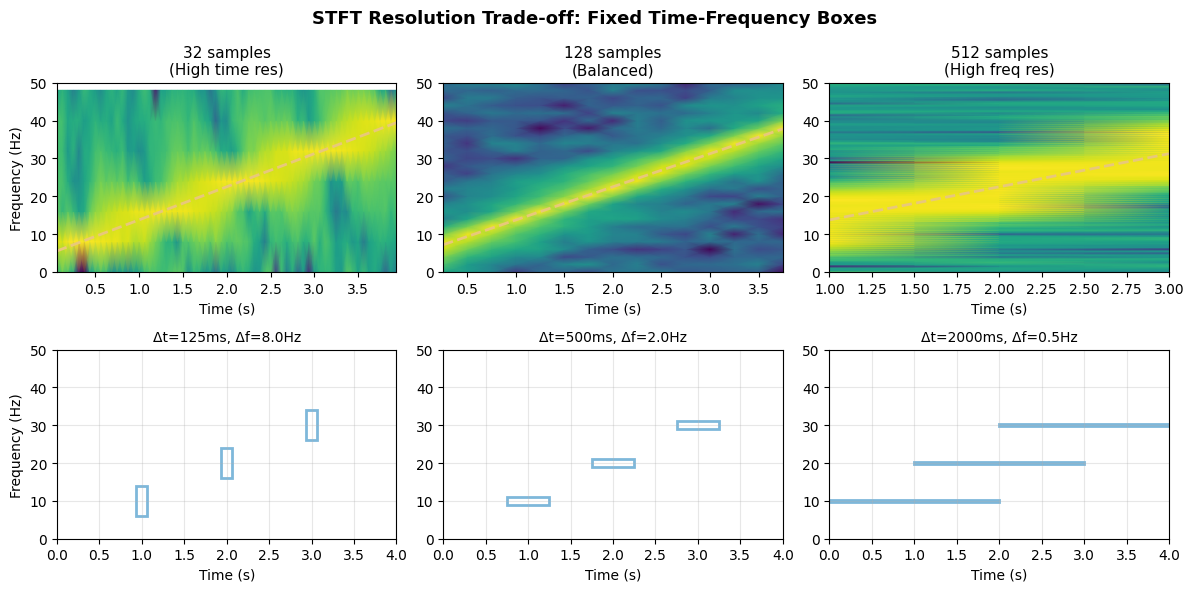

📊 Key insight: In STFT, all frequencies use the same resolution box!
   This is inefficient: high frequencies need good time resolution,
   while low frequencies need good frequency resolution.


In [7]:
# Visualization 4: STFT resolution trade-off comparison
# Same signal analyzed with different window sizes

# Create a chirp signal (frequency increases over time)
duration = 4.0  # Longer signal to accommodate large windows
t = np.linspace(0, duration, int(fs * duration), endpoint=False)
# Chirp from 5 Hz to 40 Hz
chirp = np.sin(2 * np.pi * (5 * t + (40 - 5) / (2 * duration) * t**2))
chirp += np.random.randn(len(t)) * 0.1  # Small noise

# Compare different window sizes (adjusted for fs=256)
window_sizes = [32, 128, 512]  # in samples
window_labels = ['32 samples\n(High time res)', '128 samples\n(Balanced)', '512 samples\n(High freq res)']

fig, axes = plt.subplots(2, 3, figsize=(12, 6))

# Top row: Spectrograms
for idx, (nperseg, label) in enumerate(zip(window_sizes, window_labels)):
    noverlap = nperseg // 2 if nperseg > 2 else 0
    f, t_spec, Sxx = spectrogram(chirp, fs=fs, nperseg=nperseg, noverlap=noverlap)
    
    # Limit to 0-50 Hz
    freq_mask = f <= 50
    
    ax = axes[0, idx]
    im = ax.pcolormesh(t_spec, f[freq_mask], 10 * np.log10(Sxx[freq_mask] + 1e-10),
                       shading='gouraud', cmap='viridis')
    
    # Overlay true frequency trajectory
    true_freq = 5 + (40 - 5) / duration * t_spec
    ax.plot(t_spec, true_freq, color=SECONDARY_ORANGE, linewidth=2, 
            linestyle='--', label='True frequency')
    
    ax.set_ylabel('Frequency (Hz)' if idx == 0 else '')
    ax.set_xlabel('Time (s)')
    ax.set_title(label, fontsize=11)
    ax.set_ylim([0, 50])

# Bottom row: Time-frequency resolution boxes
for idx, (nperseg, label) in enumerate(zip(window_sizes, window_labels)):
    ax = axes[1, idx]
    
    # Calculate resolution
    time_res = nperseg / fs  # seconds
    freq_res = fs / nperseg  # Hz
    
    # Draw resolution boxes at different frequencies
    frequencies = [10, 20, 30]
    times = [1.0, 2.0, 3.0]
    
    for f_center, t_center in zip(frequencies, times):
        # All boxes have same size (STFT limitation)
        rect = plt.Rectangle((t_center - time_res/2, f_center - freq_res/2),
                             time_res, freq_res, 
                             fill=False, edgecolor=PRIMARY_BLUE, linewidth=2)
        ax.add_patch(rect)
    
    ax.set_xlim([0, 4])
    ax.set_ylim([0, 50])
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Frequency (Hz)' if idx == 0 else '')
    ax.set_title(f'Δt={time_res*1000:.0f}ms, Δf={freq_res:.1f}Hz', fontsize=10)
    ax.grid(True, alpha=0.3)

fig.suptitle('STFT Resolution Trade-off: Fixed Time-Frequency Boxes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("📊 Key insight: In STFT, all frequencies use the same resolution box!")
print("   This is inefficient: high frequencies need good time resolution,")
print("   while low frequencies need good frequency resolution.")

---

<a id="summary"></a>
## 4. 📝 Summary

### Key Takeaways

1. **The FFT's limitation**
   - The FFT treats a signal as stationary (unchanging statistics over time)
   - It cannot tell you *when* a frequency appeared or disappeared
   - EEG signals are intrinsically non-stationary: frequency content evolves with cognitive state

2. **The STFT solution**
   - Slide a short analysis window over the signal
   - Compute FFT within each window → get a local frequency snapshot
   - Stack results: time × frequency → spectrogram

3. **The fundamental trade-off (Heisenberg)**
   - Short windows → good temporal resolution, poor frequency resolution
   - Long windows → good frequency resolution, poor temporal resolution
   - You cannot have both simultaneously

4. **Choosing window parameters**
   - Window length: 1–4 seconds for resting-state EEG (frequency resolution ~0.25–1 Hz)
   - Overlap: 50–75% balances temporal resolution and computation cost
   - Window type: Hann window reduces spectral leakage

### When to Use STFT vs Wavelets
- STFT: uniform time-frequency resolution across all frequencies
- Wavelets (B04b): adaptive resolution — better at low frequencies, coarser at high frequencies


---

<a id="discussion-questions"></a>
## 5. 💬 Discussion Questions

1. **Why does windowing matter?** What happens to the spectral estimate if you use a rectangular window (no tapering) vs a Hann window? Draw a diagram of what spectral leakage looks like.

2. **Resolution trade-off in practice**: You are analyzing gamma-band (30–80 Hz) transients that last ~50 ms. You also want to track alpha power (8–13 Hz) over 5-second epochs. Can the same STFT parameters serve both purposes?

3. **Overlap intuition**: An STFT with 50% overlap vs 75% overlap — how does this affect the number of time frames? The temporal resolution? The computational cost?

4. **EEG stationarity**: Under what experimental conditions might you treat EEG as approximately stationary? When is the STFT analysis clearly insufficient?

5. **Beyond visualization**: Spectrograms are often used to identify events visually. How would you quantify the "onset time" of a frequency burst detected in a spectrogram?


---

<a id="external-resources"></a>
## 6. 🔗 External Resources

### 📚 Scientific References

- **Allen, J.B. & Rabiner, L.R. (1977)** - *A unified approach to short-time Fourier analysis and synthesis* — Original STFT formulation
- **Cohen, M.X. (2014)** - *Analyzing Neural Time Series Data* (MIT Press) — Chapter 13: Time-frequency analysis
- **Mallat, S. (1999)** - *A Wavelet Tour of Signal Processing* — Chapter 4: STFT foundations

### 🎧 NotebookLM Resources

*(NotebookLM links will be added once this notebook is finalized)*

### 🔗 Next Steps

Continue to **[B04b: Wavelet Analysis](B04b_wavelet_analysis.ipynb)** for the adaptive time-frequency resolution approach using Morlet wavelets.
